# 4 · Random forest

```{math}
\hat y = \operatorname{mode}\big(h_1(x), \dots, h_T(x)\big)
```

**Family:** tree models · **Task:** classification

The video shows a 3×3 grid of jagged single-tree regions and then one smoother map:
their vote. Each tree $h_t$ is grown on a bootstrap resample of the training set and
considers only a random subset of features at each split, so the trees make
different mistakes and those mistakes partly cancel.

```{note}
The video's formula is a hard majority vote. scikit-learn's `RandomForestClassifier`
actually averages the trees' predicted probabilities (soft voting). Below we compute
both and measure how often they disagree.
```

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ml8 import data, models, scratch, plotting as P
P.use_style()
pd.set_option("display.precision", 4)

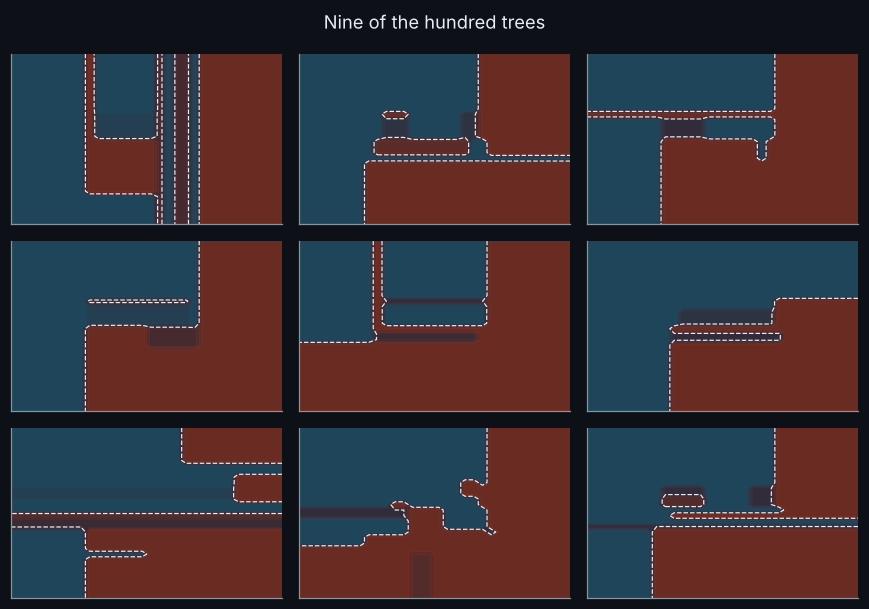

In [2]:
Xtr, ytr, Xte, yte = data.moons_arrays()
rf = models.forest(100).fit(Xtr, ytr)

fig, axes = plt.subplots(3, 3, figsize=(8, 5.6))
for ax, est in zip(axes.ravel(), rf.estimators_[:9]):
    P.plot_surface(ax, est.predict_proba(data.grid()[2])[:, 1])
fig.suptitle("Nine of the hundred trees", color=P.FG)
plt.tight_layout()

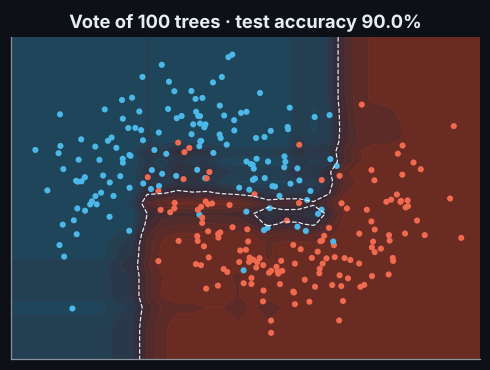

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
P.plot_surface(ax, rf, Xtr, ytr, title=f"Vote of 100 trees · test accuracy {rf.score(Xte, yte):.1%}");

## Hard vote (the video's mode) versus soft vote (scikit-learn)

In [4]:
votes = np.stack([est.predict(Xte) for est in rf.estimators_])      # T x n_test
hard = (votes.mean(axis=0) > 0.5).astype(int)                         # mode for two classes
soft = rf.predict(Xte)
print(f"hard-vote test accuracy {np.mean(hard == yte):.3f}")
print(f"soft-vote test accuracy {np.mean(soft == yte):.3f}")
print(f"points where they disagree: {np.sum(hard != soft)} of {len(yte)}")

hard-vote test accuracy 0.892
soft-vote test accuracy 0.900
points where they disagree: 3 of 120


## More trees, steadier answers

trees,1,3,5,10,25,50,100
train,0.8714,0.9393,0.9464,0.9536,0.9679,0.9643,0.9714
test,0.7417,0.8750,0.8667,0.9083,0.8917,0.8917,0.9000


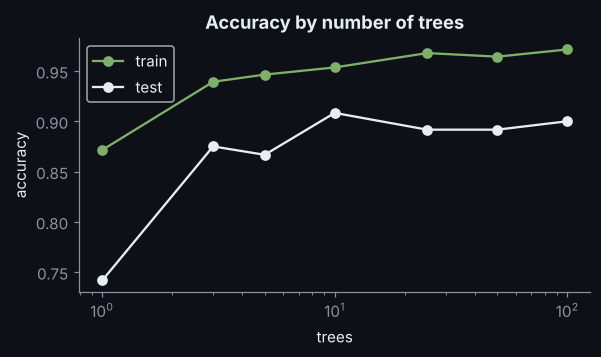

In [5]:
rows = []
for T in models.FOREST_SIZES:
    m = models.forest(T).fit(Xtr, ytr)
    rows.append({"trees": T, "train": m.score(Xtr, ytr), "test": m.score(Xte, yte)})
curve = pd.DataFrame(rows).set_index("trees")
ax = curve.plot(marker="o", logx=True, figsize=(6, 3), color=[P.GREEN, P.FG])
ax.set_ylabel("accuracy"); ax.set_title("Accuracy by number of trees");
curve.T

A single tree in the forest is worse than the tuned decision tree of chapter 3, since it
sees a resample and random features. Averaging ten or more recovers that and passes the single tuned tree. Past
that, extra trees cost time but change little: forests do not overfit by adding trees.

**Try it:** set `max_features=None` in `models.forest` so every tree sees both features.
The trees become more alike and the benefit of voting shrinks.